In [1]:
# define romania map objects
romania_map_nodes = dict(
    Arad=(91, 492), Bucharest=(400, 327), Craiova=(253, 288),
    Drobeta=(165, 299), Eforie=(562, 293), Fagaras=(305, 449),
    Giurgiu=(375, 270), Hirsova=(534, 350), Iasi=(473, 506),
    Lugoj=(165, 379), Mehadia=(168, 339), Neamt=(406, 537),
    Oradea=(131, 571), Pitesti=(320, 368), Rimnicu=(233, 410),
    Sibiu=(207, 457), Timisoara=(94, 410), Urziceni=(456, 350),
    Vaslui=(509, 444), Zerind=(108, 531))

romania_map_edges = dict(
    Arad=dict(Zerind=75, Sibiu=140, Timisoara=118),
    Bucharest=dict(Urziceni=85, Pitesti=101, Giurgiu=90, Fagaras=211),
    Craiova=dict(Drobeta=120, Rimnicu=146, Pitesti=138),
    Drobeta=dict(Mehadia=75),
    Eforie=dict(Hirsova=86),
    Fagaras=dict(Sibiu=99),
    Hirsova=dict(Urziceni=98),
    Iasi=dict(Vaslui=92, Neamt=87),
    Lugoj=dict(Timisoara=111, Mehadia=70),
    Oradea=dict(Zerind=71, Sibiu=151),
    Pitesti=dict(Rimnicu=97),
    Rimnicu=dict(Sibiu=80),
    Urziceni=dict(Vaslui=142))

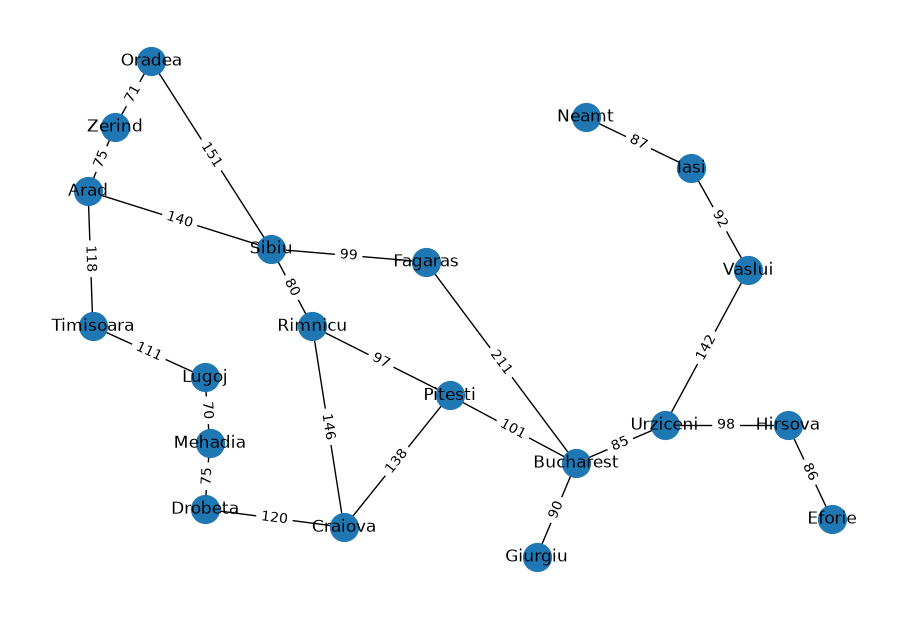

In [2]:
# draw romania map using networkx package
import networkx as nx
import matplotlib.pyplot as plt

G=nx.Graph()
#G.add_node(1,pos=(1,1))
for node in romania_map_nodes.keys():
    G.add_node(node, pos=romania_map_nodes[node])

#G.add_edge(1,2,weight=0.5)
for a in list(romania_map_edges.keys()):
    for (b, dist) in romania_map_edges[a].items():
        G.add_edge(a, b, weight=dist)
        G.add_edge(b, a, weight=dist)

# draw
plt.figure(1,figsize=(9,6))
pos=nx.get_node_attributes(G,'pos')
nx.draw(G, pos, with_labels='True', node_size=400)
labels = nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G,pos,edge_labels=labels)
plt.savefig("romania.png")

In [3]:
# define Graph Search Problem and Node classes
import numpy as np
class GraphProblem():
    """The problem of searching a graph from one node to another."""
    def __init__(self, initial, goal, nodes, edges):
        self.initial = initial   #initial or start state
        self.goal = goal         #goal state
        self.nodes = nodes       #dictionaries of nodes in the graph
        self.edges = edges       #dictionaries of edges in the graph
        for a in list(self.edges.keys()):
            for (b, dist) in self.edges[a].items():
                self.edges.setdefault(b, {})[a] = dist  #set the distance between two vertices

    def actions(self, startNode):
        """The actions at a graph node are just its neighbors --- a list of neighbor nodes to visit from startNode."""
        return list(self.edges.get(startNode).keys())

    def result(self, state, action):
        """The result of going to a neighbor is just that neighbor."""
        return action
    
    def goal_test(self, state):
        """Return True if the state is a goal."""
        return state == self.goal

    def path_cost(self, cost_so_far, A, action, B):
        """Calculate the cost from node A to node B including the previous cost (cost_so_far)"""
        links = self.edges.setdefault(A, {})
        if B is None:
            cost_A_B = np.inf
        else:
            cost_A_B = links.get(B)
        return cost_so_far + cost_A_B

    def find_min_edge(self):
        """Find minimum value of edges."""
        m = np.inf
        for d in self.edges.values():
            local_min = min(d.values())
            m = min(m, local_min)
        return m
    
    def distance(self, a, b):
        """The Euclidean distance between two (x, y) points."""
        xA, yA = a
        xB, yB = b
        return np.hypot((xA - xB), (yA - yB))

    def h(self, node):
        """heuristic function is the straight-line distance from a node's state to goal."""
        if type(node) is str:
            return int(self.distance(self.nodes[node], self.nodes[self.goal]))
        return int(self.distance(self.nodes[node.state], self.nodes[self.goal]))

class Node:
    """A node in a search tree."""
    def __init__(self, state, parent=None, action=None, path_cost=0):
        """Create a search tree Node, derived from a parent by an action."""
        self.state = state
        self.parent = parent
        self.action = action
        self.path_cost = path_cost
        self.depth = 0
        if parent:
            self.depth = parent.depth + 1

    def __repr__(self):
        return "<Node {}>".format(self.state)   #return the string representation of a node

    def __lt__(self, node):
        return self.state < node.state   #return the comparison of the current node (self) with another node

    def expand(self, problem):
        """List the nodes reachable in one step from this node."""
        return [self.child_node(problem, action)
                for action in problem.actions(self.state)]

    def child_node(self, problem, action):
        """Return the next child node if performing the given action"""
        next_state = problem.result(self.state, action)
        next_node = Node(next_state, self, action, problem.path_cost(self.path_cost, self.state, action, next_state))
        return next_node

    def solution(self):
        """Return the sequence of actions to go from the root to this node."""
        return [node.action for node in self.path()[1:]]

    def path(self):
        """Return a list of nodes forming the path from the root to this node."""
        node, path_back = self, []
        while node:
            path_back.append(node)
            node = node.parent
        return list(reversed(path_back))

    def __eq__(self, other):
        """Compare this with other instances for equality"""
        return isinstance(other, Node) and self.state == other.state

    def __hash__(self):
        """return the hash value of the state"""
        return hash(self.state)

In [4]:
# Breadth first search implementation
from collections import deque
def breadth_first_graph_search(problem):
    node = Node(problem.initial)
    if problem.goal_test(node.state):
        return node
    frontier = deque([node])
    explored = set()
    while frontier:
        node = frontier.popleft()
        explored.add(node.state)
        for child in node.expand(problem):
            if child.state not in explored and child not in frontier:
                if problem.goal_test(child.state):
                    return child
                frontier.append(child)
    return None

Solution:  ['Sibiu', 'Fagaras', 'Bucharest']
Path:  [<Node Arad>, <Node Sibiu>, <Node Fagaras>, <Node Bucharest>]


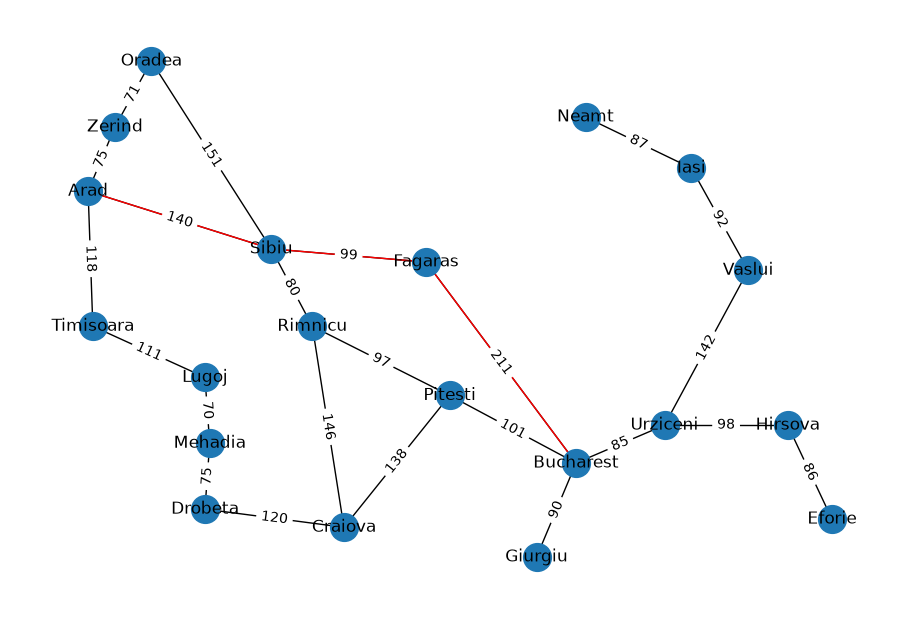

In [5]:
# Visualize Breadth first search result
romaniaProblem = GraphProblem('Arad', 'Bucharest', romania_map_nodes, romania_map_edges)
bfs_node = breadth_first_graph_search(romaniaProblem)
print('Solution: ', bfs_node.solution())
print('Path: ', bfs_node.path())
# draw bfs solution map
plt.figure(2,figsize=(9,6))
pos=nx.get_node_attributes(G,'pos')
path_nodes = [node.state for node in bfs_node.path()]
solution_edges = []
for i in range(len(path_nodes)-1):
    solution_edges.append((path_nodes[i], path_nodes[i+1]))
# draw default romania map
nx.draw(G, pos, with_labels='True', node_size=400)    #, edge_color=edge_colors
# highlight the edges in the solution with red color
nx.draw_networkx_edges(G, pos, solution_edges, edge_color='red')
# draw the edge labels (weight values)
labels = nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G,pos,edge_labels=labels)
plt.savefig("romania_bfs_solution.png")

In [6]:
# Depth first search implementation
def depth_first_graph_search(problem):
    frontier = [(Node(problem.initial))]  # Stack
    explored = set()
    while frontier:
        node = frontier.pop()
        if problem.goal_test(node.state):
            return node
        explored.add(node.state)
        frontier.extend(child for child in node.expand(problem)
                        if child.state not in explored and child not in frontier)
    return None

Solution:  ['Timisoara', 'Lugoj', 'Mehadia', 'Drobeta', 'Craiova', 'Pitesti', 'Bucharest']
Path:  [<Node Arad>, <Node Timisoara>, <Node Lugoj>, <Node Mehadia>, <Node Drobeta>, <Node Craiova>, <Node Pitesti>, <Node Bucharest>]


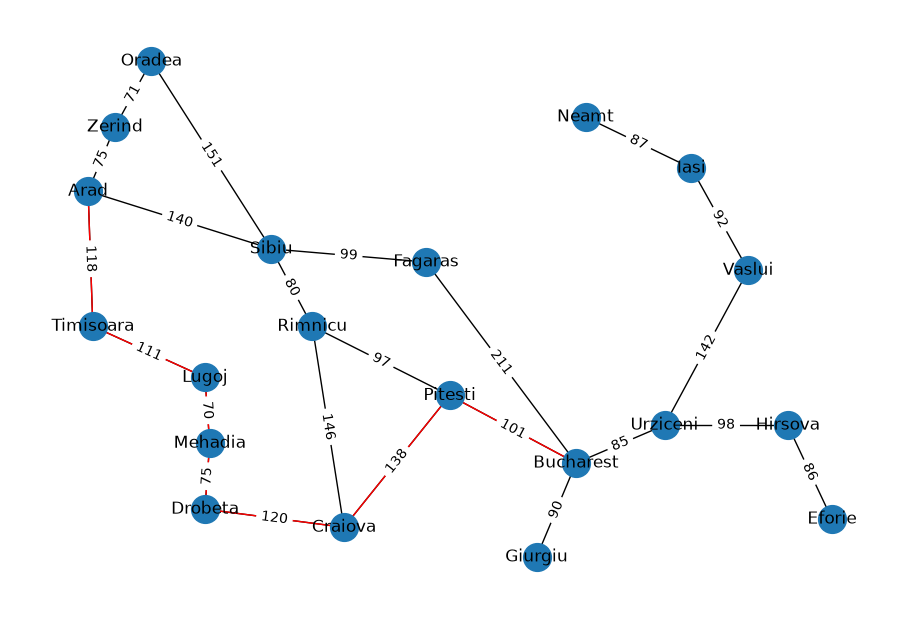

In [7]:
# Visualize Depth first search result
dfs_node = depth_first_graph_search(romaniaProblem)
print('Solution: ', dfs_node.solution())
print('Path: ', dfs_node.path())
#draw dfs solution map
plt.figure(3,figsize=(9,6))
pos=nx.get_node_attributes(G,'pos')
path_nodes = [node.state for node in dfs_node.path()]
solution_edges = []
for i in range(len(path_nodes)-1):
    solution_edges.append((path_nodes[i], path_nodes[i+1]))
#draw default romania map
nx.draw(G, pos, with_labels='True', node_size=400)    #, edge_color=edge_colors
#highlight the edges in the solution with red color
nx.draw_networkx_edges(G, pos, solution_edges, edge_color='red')
#draw the edge labels (weight values)
labels = nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G,pos,edge_labels=labels)
plt.savefig("romania_dfs_solution.png")

In [8]:
# Uniform cost search implementation
import heapq
def uniform_cost_search(problem):
    # For uniform cost search, we only use the past cost g(n) - the path cost from the root node up to the current node
    node = Node(problem.initial)         # Define the root node - start node 
    frontier = [(node.path_cost, node)]  # Define the heap to store the explored tree with associated cost
    visited = {}                         # Store visited nodes with their best exploration cost so far
    while frontier:
        cost, node = heapq.heappop(frontier)  # Get the node with lowest path cost from the frontier
        # TODO 1: check if node is the goal, then return node
        if problem.goal_test(node.state):
            return node
        # TODO 2: check if node is in visited and the associated cost of node in visited < cost, then continue
        if node in visited and visited[node] < cost:
            continue
        # TODO 3: mark node as visited with its current exploring cost
        visited[node] = cost
        # Explore neighbors of the node
        for neighbor in node.expand(problem):
            if neighbor not in visited:
                # TODO 4: use heapq.heappush to append new entry (neighbor.path_cost, neighbor) into frontier
                heapq.heappush(frontier,(neighbor.path_cost, neighbor))
    return None

Solution:  ['Sibiu', 'Rimnicu', 'Pitesti', 'Bucharest']
Path:  [<Node Arad>, <Node Sibiu>, <Node Rimnicu>, <Node Pitesti>, <Node Bucharest>]


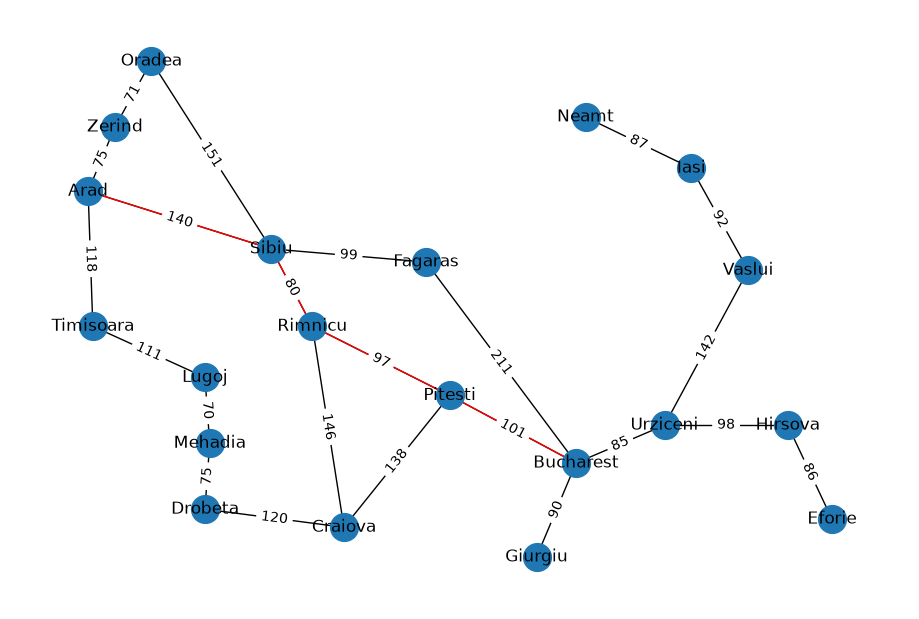

In [9]:
# Visualize Uniform cost search result
ucs_node = uniform_cost_search(romaniaProblem)
print('Solution: ', ucs_node.solution())
print('Path: ', ucs_node.path())
# draw ucs solution map
plt.figure(3,figsize=(9,6))
pos=nx.get_node_attributes(G,'pos')
path_nodes = [node.state for node in ucs_node.path()]
solution_edges = []
for i in range(len(path_nodes)-1):
    solution_edges.append((path_nodes[i], path_nodes[i+1]))
# draw default romania map
nx.draw(G, pos, with_labels='True', node_size=400)    #, edge_color=edge_colors
# highlight the edges in the solution with red color
nx.draw_networkx_edges(G, pos, solution_edges, edge_color='red')
# draw the edge labels (weight values)
labels = nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G,pos,edge_labels=labels)
plt.savefig("romania_ucs_solution.png")

In [10]:
# A star search implementation    
def astar_search(problem, h=None):
    # for A*, we use f(n) = g(n) + h(n), g(n) is the path cost so far and h(n) is the heuristic function
    # h(n) is defined by the straight line distance between the current node and the goal node    
    node = Node(problem.initial)                         # Define the root node - start node 
    frontier = [(node.path_cost+problem.h(node), node)]  # Define the heap to store the explored tree with associated cost
    visited = {}                                         # Store visited nodes with their best exploration cost so far
    while frontier:
        cost, node = heapq.heappop(frontier)  # Get the node with lowest path cost from the frontier
        # TODO 1: check if node is the goal, then return node
        if problem.goal_test(node.state):
            return node
        # TODO 2: check if node is in visited and the associated cost of node in visited < cost, then continue
        if node in visited and visited[node] < cost:
            continue
        # TODO 3: mark node as visited with its current exploring cost
        visited[node] = cost
        # Explore neighbors of the node
        for neighbor in node.expand(problem):
            if neighbor not in visited:
                # TODO 4: use heapq.heappush to append new entry (neighbor.path_cost+problem.h(node), neighbor) into frontier
                heapq.heappush(frontier,(neighbor.path_cost+problem.h(node), neighbor))
    return None

Solution:  ['Sibiu', 'Rimnicu', 'Pitesti', 'Bucharest']
Path:  [<Node Arad>, <Node Sibiu>, <Node Rimnicu>, <Node Pitesti>, <Node Bucharest>]


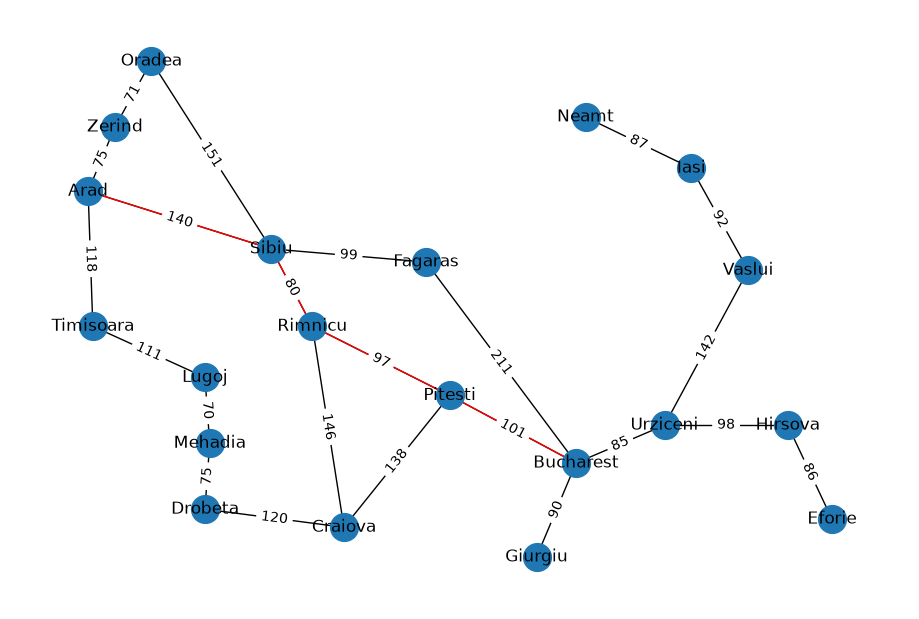

In [11]:
# Visualize A star search result
astar_node = astar_search(romaniaProblem)
print('Solution: ', astar_node.solution())
print('Path: ', astar_node.path())
# draw astar solution map
plt.figure(3,figsize=(9,6))
pos=nx.get_node_attributes(G,'pos')
path_nodes = [node.state for node in astar_node.path()]
solution_edges = []
for i in range(len(path_nodes)-1):
    solution_edges.append((path_nodes[i], path_nodes[i+1]))
# draw default romania map
nx.draw(G, pos, with_labels='True', node_size=400)    #, edge_color=edge_colors
# highlight the edges in the solution with red color
nx.draw_networkx_edges(G, pos, solution_edges, edge_color='red')
# draw the edge labels (weight values)
labels = nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G,pos,edge_labels=labels)
plt.savefig("romania_astar_solution.png")

In [12]:
romaniaProblem = GraphProblem('Arad', 'Vaslui', romania_map_nodes, romania_map_edges)
bfs_node = breadth_first_graph_search(romaniaProblem)
print('Solution: ', bfs_node.solution())
print('Path: ', bfs_node.path())

dfs_node = depth_first_graph_search(romaniaProblem)
print('Solution: ', dfs_node.solution())
print('Path: ', dfs_node.path())

ucs_node = uniform_cost_search(romaniaProblem)
print('Solution: ', ucs_node.solution())
print('Path: ', ucs_node.path())

astar_node = astar_search(romaniaProblem)
print('Solution: ', astar_node.solution())
print('Path: ', astar_node.path())

Solution:  ['Sibiu', 'Fagaras', 'Bucharest', 'Urziceni', 'Vaslui']
Path:  [<Node Arad>, <Node Sibiu>, <Node Fagaras>, <Node Bucharest>, <Node Urziceni>, <Node Vaslui>]
Solution:  ['Timisoara', 'Lugoj', 'Mehadia', 'Drobeta', 'Craiova', 'Pitesti', 'Bucharest', 'Urziceni', 'Vaslui']
Path:  [<Node Arad>, <Node Timisoara>, <Node Lugoj>, <Node Mehadia>, <Node Drobeta>, <Node Craiova>, <Node Pitesti>, <Node Bucharest>, <Node Urziceni>, <Node Vaslui>]
Solution:  ['Sibiu', 'Rimnicu', 'Pitesti', 'Bucharest', 'Urziceni', 'Vaslui']
Path:  [<Node Arad>, <Node Sibiu>, <Node Rimnicu>, <Node Pitesti>, <Node Bucharest>, <Node Urziceni>, <Node Vaslui>]
Solution:  ['Sibiu', 'Rimnicu', 'Pitesti', 'Bucharest', 'Urziceni', 'Vaslui']
Path:  [<Node Arad>, <Node Sibiu>, <Node Rimnicu>, <Node Pitesti>, <Node Bucharest>, <Node Urziceni>, <Node Vaslui>]
